## 1. Data Loading & Inspection

In [7]:
%pip install -U datasets huggingface_hub

  Using cached datasets-5.1.0-py3-none-any.whl.metadata (24 kB)
  Using cached huggingface_hub-2.2.0-py3-none-any.whl.metadata (16 kB)
Using cached datasets-5.1.0-py3-none-any.whl (604 kB)
Using cached huggingface_hub-2.2.0-py3-none-any.whl (839 kB)

  Attempting uninstall: huggingface_hub

    Found existing installation: huggingface-hub 0.24.7

    Uninstalling huggingface-hub-0.24.7:

      Successfully uninstalled huggingface-hub-0.24.7

   ---------------------------------------- 0/2 [huggingface_hub]
   ---------------------------------------- 0/2 [huggingface_hub]
   ---------------------------------------- 0/2 [huggingface_hub]
   ---------------------------------------- 0/2 [huggingface_hub]
   ---------------------------------------- 0/2 [huggingface_hub]
   ---------------------------------------- 0/2 [huggingface_hub]
   ---------------------------------------- 0/2 [huggingface_hub]
   ---------------------------------------- 0/2 [huggingface_hub]
   -----------------------

In [18]:
import platform
import torch
from transformers import BertTokenizer, AutoModelForSequenceClassification

print(torch.__version__)
print(torch.cuda.is_available())

print("Python version      :", platform.python_version())
print("PyTorch version     :", torch.__version__)
print("GPU available       :", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

2.11.0+cu128
True
Python version      : 3.11.5
PyTorch version     : 2.11.0+cu128
GPU available       : True


In [ ]:
from datasets import load_dataset

dataset = load_dataset("cardiffnlp/tweet_eval", "sentiment")
print(dataset)

c:\Users\avigd\AppData\Local\Programs\Python\Python311\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\avigd\.cache\huggingface\hub\datasets--cardiffnlp--tweet_eval. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\avigd\AppData\Local\Programs\Python\Python311\Lib\site-packages\huggingface_hub\f

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 45615
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 12284
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


In [ ]:
for sample in dataset["train"].shuffle().select(range(2)):
    if sample["label"] == 0:
        print("Negative")
    elif sample["label"] == 1:
        print("Neutral")
    elif sample["label"] == 2:
        print("Positive")
    else:
        print("Not managed")
    print(sample["text"][:250], "...\n")

Positive
Few more hours to iPhone 6s launch and im still using the 4th generation ^_^ ...

Positive
Last night we were named NZ's 27th fastest growing co. in the Deloitte Fast 50. Our 2nd year making the list and we are totally thrilled! ...



## 2. Tokenization Pipeline

In [20]:
MAX_LENGTH = 128
BATCH_SIZE = 32

tokenizer = BertTokenizer.from_pretrained("distilbert/distilbert-base-uncased", do_lower_case=True)
print("Tokenizer loaded:", tokenizer.name_or_path)

Tokenizer loaded: distilbert/distilbert-base-uncased


In [16]:
def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        add_special_tokens=True,
        max_length=MAX_LENGTH,
        padding="max_length",
        truncation=True,
        return_attention_mask=True,
        return_token_type_ids=True,
    )

encoded = dataset.map(tokenize_batch, batched=True).shuffle().rename_column("label", "labels")
encoded.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"],
)

train_ds = encoded["train"]
test_ds = encoded["test"]

## 3. Fine-Tuning Setup

In [19]:
model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=3,
)

model.to(device)
model.config

c:\Users\avigd\AppData\Local\Programs\Python\Python311\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\avigd\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1010.41it/s]
[transformers] DistilB

DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForMaskedLM"
  ],
  "attention_dropout": 0.1,
  "bos_token_id": null,
  "dim": 768,
  "dropout": 0.1,
  "dtype": "float32",
  "eos_token_id": null,
  "hidden_dim": 3072,
  "id2label": {
    "0": "LABEL_0",
    "1": "LABEL_1",
    "2": "LABEL_2"
  },
  "initializer_range": 0.02,
  "label2id": {
    "LABEL_0": 0,
    "LABEL_1": 1,
    "LABEL_2": 2
  },
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "tie_word_embeddings": true,
  "transformers_version": "5.19.0",
  "vocab_size": 30522
}

In [21]:
import numpy as np
import evaluate
from transformers import TrainingArguments, Trainer

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    accuracy = accuracy_metric.compute(predictions=predictions, references=labels)
    f1 = f1_metric.compute(predictions=predictions, references=labels, average="macro")
    return {"accuracy": accuracy["accuracy"], "f1_macro": f1["f1"]}

EPOCHS = 3

training_args = TrainingArguments(
    output_dir="./bert-tweet",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=5e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

history = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.613029,0.719015,0.673315,0.668999
2,0.443273,0.810162,0.660941,0.661534
3,0.275846,0.933905,0.682107,0.679725


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  3.50it/s]


## 4. Evaluation & Calibration

In [22]:
eval_metrics = trainer.evaluate(eval_dataset=test_ds)
print(eval_metrics)

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.275846,0.933905,3,0.682107,0.679725


{'eval_loss': 0.9339048862457275, 'eval_accuracy': 0.6821068056007815, 'eval_f1_macro': 0.6797253705076782}


In [23]:
predictions_output = trainer.predict(test_ds)
logits = predictions_output.predictions
probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()

predicted_classes = np.argmax(probs, axis=-1)
confidence_scores = probs[np.arange(len(probs)), predicted_classes]

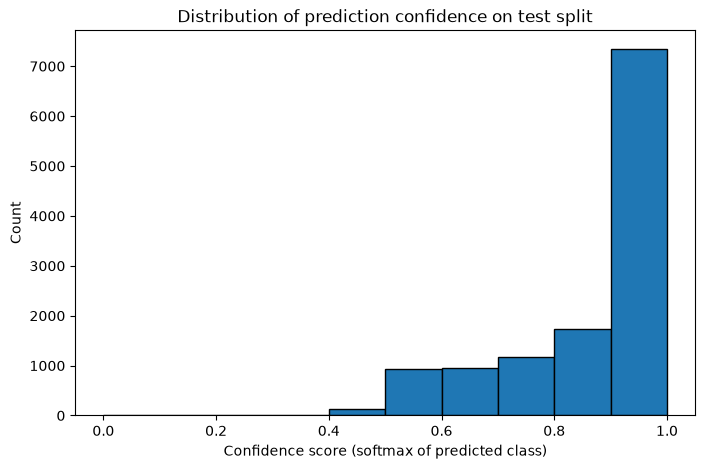

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(confidence_scores, bins=np.arange(0, 1.1, 0.1), edgecolor="black")
plt.xlabel("Confidence score (softmax of predicted class)")
plt.ylabel("Count")
plt.title("Distribution of prediction confidence on test split")
plt.show()

Here the accuracy is 0.68 (that is not very high), but the majority of the confidence score is around 0.9-1.0.
-> it means the model is overconfident.

## 5. Attention Inspection

In [46]:
import random as r

a_text = dataset["train"][r.randint(0, len(dataset["train"])-1)]["text"]
print(a_text)

When you're sick of waiting for a book to come in from BN so you ask your husband to order it via Amazon Prime. Yup. Getting it Saturday.


In [47]:
from transformers import AutoModel

base_model = AutoModel.from_pretrained("distilbert-base-uncased", output_attentions=True)
base_model.eval()

inputs = tokenizer(
    a_text,
    return_tensors="pt",
    truncation=True,
    max_length=MAX_LENGTH,
)

with torch.no_grad():
    outputs = base_model(**inputs)

last_layer_attn = outputs.attentions[-1][0]
avg_attn = last_layer_attn.mean(dim=0)

cls_attention = avg_attn[0]

tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 636.63it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


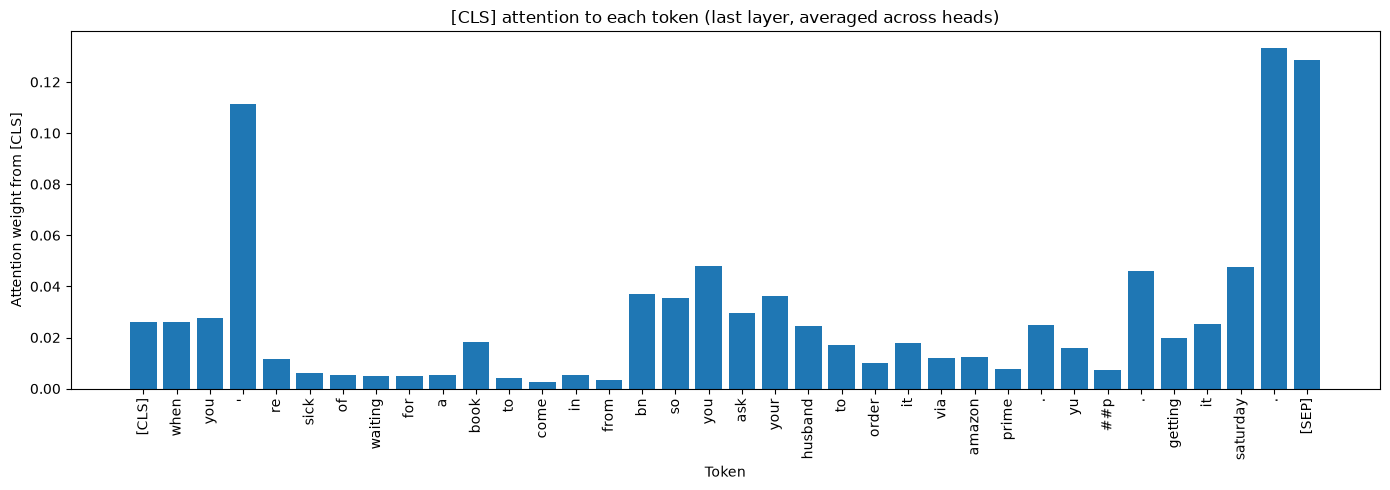

In [48]:
plt.figure(figsize=(14, 5))
plt.bar(range(len(tokens)), cls_attention.numpy())
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.xlabel("Token")
plt.ylabel("Attention weight from [CLS]")
plt.title("[CLS] attention to each token (last layer, averaged across heads)")
plt.tight_layout()
plt.show()